# 03. Statistical tests

**Question:** which of the differences seen in notebook 02 are real, and which could be random noise?

- **Categorical and 1-5 score columns:** chi-square test of independence with Cramer's V as the effect size.
- **Numeric columns:** Mann-Whitney U test (leavers vs stayers) with the rank-biserial correlation as the effect size.

With 10,000 rows, even tiny differences can give very small p-values. So the **effect size** is the more useful number. A Bonferroni correction is applied because many tests are run at once.

In [1]:
import sys
from pathlib import Path

sys.path.append(str(Path.cwd().parent / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import Markdown, display

from hr_utils import (load_raw, load_clean, rate_table, segment_table, plot_rate, savefig, save_table,
                      SEGMENT_FACTORS, PROCESSED, ACCENT, BASE)

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 160)
sns.set_theme(style="whitegrid")

from scipy import stats

In [2]:
df = load_clean()
y = df["attrition_flag"]

cat_cols = ["overtime", "business_travel", "department", "job_role", "gender", "marital_status", "education",
            "job_level", "environment_satisfaction", "job_satisfaction", "job_involvement", "work_life_balance"]
num_cols = ["age", "salary", "distance_from_home", "salary_hike_pct", "total_experience_years",
            "years_at_company", "years_in_role", "years_since_promotion", "companies_worked_before"]

def chi_square(col):
    table = pd.crosstab(df[col], y)
    chi2, p, dof, _ = stats.chi2_contingency(table)
    v = np.sqrt(chi2 / (table.to_numpy().sum() * (min(table.shape) - 1)))
    return {"factor": col, "test": "chi-square", "statistic": round(chi2, 1), "p_value": p,
            "effect_size": round(v, 3), "effect_measure": "Cramer's V"}

def mann_whitney(col):
    a, b = df.loc[y == 1, col], df.loc[y == 0, col]
    u, p = stats.mannwhitneyu(a, b, alternative="two-sided")
    r = 2 * u / (len(a) * len(b)) - 1          # positive = leavers have higher values
    return {"factor": col, "test": "Mann-Whitney U", "statistic": round(float(u), 0), "p_value": p,
            "effect_size": round(r, 3), "effect_measure": "rank-biserial (+ = leavers higher)"}

res = pd.DataFrame([chi_square(c) for c in cat_cols] + [mann_whitney(c) for c in num_cols])
alpha = 0.05
res["bonferroni_alpha"] = alpha / len(res)
res["significant_after_correction"] = res["p_value"] < res["bonferroni_alpha"]
res["abs_effect"] = res["effect_size"].abs()
res["effect_strength"] = pd.cut(res["abs_effect"], bins=[-1, 0.05, 0.10, 0.30, 1],
                                labels=["negligible", "very small", "small", "medium or larger"]).astype(str)
res = res.sort_values("abs_effect", ascending=False).reset_index(drop=True)

shown = res.assign(p_value=res["p_value"].map("{:.2e}".format))
shown[["factor", "test", "effect_size", "effect_measure", "effect_strength", "p_value", "significant_after_correction"]]

,factor,test,effect_size,effect_measure,effect_strength,p_value,significant_after_correction
0,environment_satisfaction,chi-square,0.220,Cramer's V,small,3.23e-103,True
1,distance_from_home,Mann-Whitney U,0.207,rank-biserial (+ = leavers higher),small,1.41e-50,True
2,job_involvement,chi-square,0.181,Cramer's V,small,6.33e-70,True
3,years_since_promotion,Mann-Whitney U,0.170,rank-biserial (+ = leavers higher),small,3.28e-35,True
4,work_life_balance,chi-square,0.167,Cramer's V,small,2.34e-59,True
5,business_travel,chi-square,0.142,Cramer's V,small,1.34e-44,True
6,job_satisfaction,chi-square,0.091,Cramer's V,very small,6.35e-17,True
7,overtime,chi-square,0.058,Cramer's V,very small,5.72e-09,True
8,job_level,chi-square,0.030,Cramer's V,negligible,2.67e-01,False
9,job_role,chi-square,0.027,Cramer's V,negligible,7.66e-01,False


In [3]:
sig = res[res["significant_after_correction"]]
not_sig = res[~res["significant_after_correction"]]
display(Markdown(f"**{len(res)} tests, Bonferroni threshold p < {alpha / len(res):.4f}.**"))
display(Markdown("Significant after correction (strongest first): " + ", ".join(f"`{f}`" for f in sig["factor"])))
display(Markdown("Not significant: " + ", ".join(f"`{f}`" for f in not_sig["factor"])))
save_table(res.drop(columns=["abs_effect"]), "statistical_tests")

**21 tests, Bonferroni threshold p < 0.0024.**

Significant after correction (strongest first): `environment_satisfaction`, `distance_from_home`, `job_involvement`, `years_since_promotion`, `work_life_balance`, `business_travel`, `job_satisfaction`, `overtime`

Not significant: `job_level`, `job_role`, `department`, `marital_status`, `education`, `years_in_role`, `total_experience_years`, `salary_hike_pct`, `age`, `companies_worked_before`, `salary`, `gender`, `years_at_company`

## Correlation of numeric columns with attrition

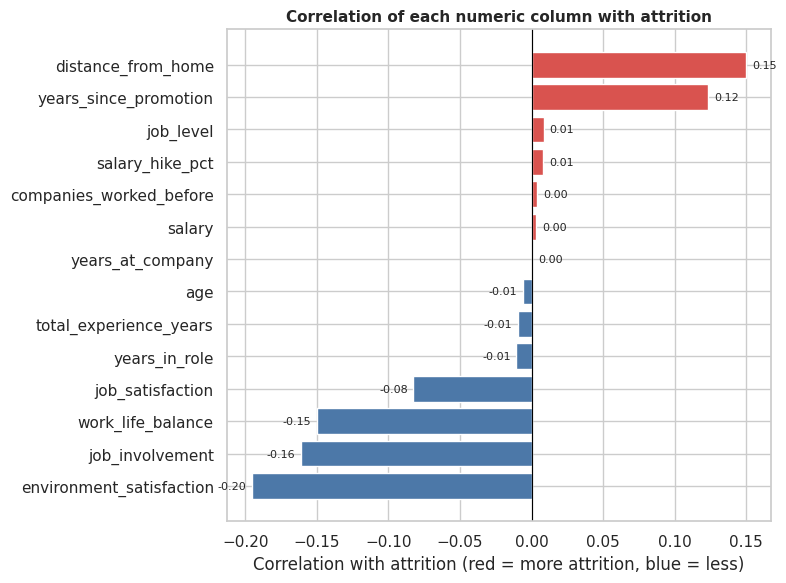

In [4]:
corr_cols = ["environment_satisfaction", "job_involvement", "work_life_balance", "job_satisfaction",
             "distance_from_home", "years_since_promotion", "salary", "age", "total_experience_years",
             "years_at_company", "years_in_role", "salary_hike_pct", "companies_worked_before", "job_level"]
corr = df[corr_cols].corrwith(y).sort_values()

fig, ax = plt.subplots(figsize=(8, 6))
colors = [ACCENT if v > 0 else BASE for v in corr]
ax.barh(corr.index, corr.values, color=colors)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlabel("Correlation with attrition (red = more attrition, blue = less)")
ax.set_title("Correlation of each numeric column with attrition", fontsize=11, fontweight="bold")
for i, v in enumerate(corr.values):
    ax.text(v + (0.004 if v >= 0 else -0.004), i, f"{v:.2f}", va="center", ha="left" if v >= 0 else "right", fontsize=8)
fig.tight_layout()
savefig(fig, "03_correlation_with_attrition")
plt.show()

## Employee_ID (artifact check)

The ID number also shows a clear link with attrition, as seen in notebook 01. This is kept out of the table above because it is a data artifact and not a business factor.

In [5]:
art = mann_whitney("employee_id")
print(f"Employee_ID: rank-biserial effect = {art['effect_size']}, p-value = {art['p_value']:.2e}")

Employee_ID: rank-biserial effect = 0.251, p-value = 1.14e-73


## Conclusion

- The differences seen in notebook 02 for **environment satisfaction, work-life balance, job involvement, distance from home, years since promotion and business travel** are statistically significant and not small by chance.
- **Overtime** and **job satisfaction** are significant but have a smaller effect.
- **Salary, age, experience, tenure, gender, education, department, job role and marital status** do not show a reliable link with attrition in this data.